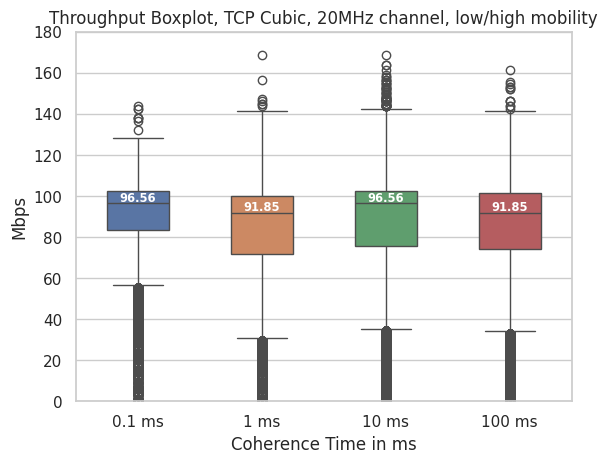

In [121]:
import matplotlib.pyplot as plt
import numpy as np
import sys
import os
import seaborn as sns
import csv

# TODO: High mobility
# TODO: DONE Median neben Plot
# TODO: Munich outdoor
# TODO: 80Mhz Kanal
# TODO: IQR (Inter quantil distanzen) Was genau meinte ich damit? 0.25, 0.75, 0.05, 0.95 und outlier
# TODO: DONE Jupyter
# TODO: DONE Zeit messen
# TODO: DONE Zeit plotten, durchschnitt im throughput?
# TODO: DONE Kein Raytracer, kein walk: Kein Crash ohne raytracer, crash mit walk
# TODO: DONE Watchdog script
# TODO: Watchdog script doesn't exit everything cleanly, improvements needed
# TODO: Relative paths
# TODO: DONE Steapcounter (channel calculations) in server

# TODO: Make this path relative!!!
# Set the path to the folder with the throughput results
basepath = "/home/ccs-lab/jan.zabel/ns-allinone-3.40/ns-3.40/tp_res_7/"

# Read Throughput from CSV files and return a list
def readThroughput(pathname):
    throughputs = {}
    times = [1, 10, 100, 1000]

    # Go trough all the coherence times
    for i in times:
        throughputs[i] = []

        # Go through the number of experiments
        for j in range (100):
            fname = f"{basepath}throughput_results_{i}_{j+1}.csv"
            try:
                with open(fname, newline='') as csvfile:
                    spamreader = csv.reader(csvfile, delimiter=' ', quotechar='|')
                    # Skip the header line, Strings make for terrible numbers
                    header = next(spamreader, None)

                    # Put the data from the csv into the dictionary at the coherence time
                    for row in spamreader:
                        t_var = ', '.join(row).split(",")[1]
                        throughputs[i].append(float(t_var))
            except FileNotFoundError:
                # print("File ", fname, " not found")
                continue
    # Return all the throughput values at one
    return [throughputs[1], throughputs[10], throughputs[100],throughputs[1000]]

throughput = readThroughput(basepath)

box_plot = sns.boxplot(data=throughput, widths=0.5)

# Write medians onto the plot (slightly above the median line)
medians = [np.median(t) for t in throughput]

vertical_offset = [m * 0.01 for m in medians]

for xtick in box_plot.get_xticks():
    box_plot.text(
        xtick,
        medians[xtick] + vertical_offset[xtick],
        f'{medians[xtick]:.2f}',
        horizontalalignment='center',
        size='x-small',
        color='white',
        weight='semibold'
    )

plt.xlabel("Coherence Time in ms")
plt.ylabel("Mbps")

plt.xticks(ticks=[0, 1, 2, 3], labels=["0.1 ms", "1 ms", "10 ms", "100 ms"])
plt.ylim(0, 180)

plt.title("Throughput Boxplot, TCP Cubic, 20MHz channel, low/high mobility")

plt.savefig("throughput_boxplot.png")

# TODO: Why some very high throughput sometimes?


Text(0.5, 1.0, 'Computation time to fixed coherence time')

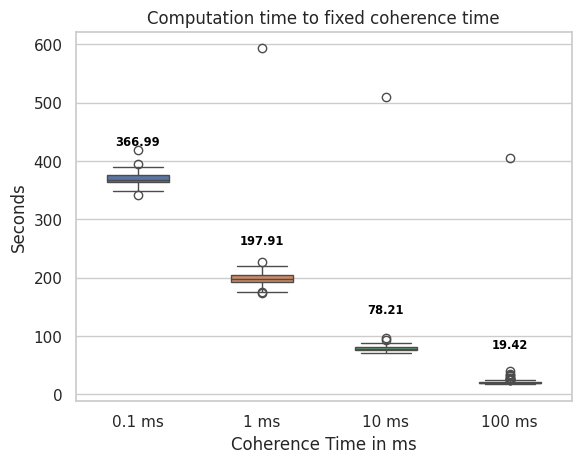

In [116]:
# Plot the time
timepath = '/home/ccs-lab/jan.zabel/ns-allinone-3.40/ns-3.40/contrib/sionna/examples/computationtime.csv'
# os.listdir('.')

def readTime(fname):
    comp_times = {}
    times = [1, 10, 100, 1000]
    # Setup dict
    for i in times:
        comp_times[i] = []
    try:
        with open(fname, newline='') as csvfile:
            spamreader = csv.reader(csvfile, delimiter=',', quotechar='|')
            # Put the data from the csv into the dictionary at the coherence time
            for line in spamreader:
                # Line value is a string, turn into int to use as index
                comp_times[int(line[0])].append(float(line[1]))
    except FileNotFoundError:
        print(f"Could not {timepath} file.")

    return comp_times

timeValue = readTime(timepath)

# print(timeValue)

box_plot = sns.boxplot(data=timeValue, widths=0.5)

# Write medians onto the plot (slightly above the median line)
medians = [np.median(timeValue[t]) for t in timeValue]

for xtick in box_plot.get_xticks():
    box_plot.text(
        xtick,
        medians[xtick] + 60,
        f'{medians[xtick]:.2f}',
        horizontalalignment='center',
        size='x-small',
        color='black',
        weight='semibold'
    )

plt.xlabel("Coherence Time in ms")
plt.ylabel("Seconds")

plt.xticks(ticks=[0, 1, 2, 3], labels=["0.1 ms", "1 ms", "10 ms", "100 ms"])

plt.title("Computation time to fixed coherence time")

# plt.savefig("throughput_boxplot.png")
# TODO: Why the outliers?